In [2]:
%pip install datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.3/608.3 kB 15.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [datasets]━━ 3/4 [datasets]ess]
Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.6/245.6 MB 75.0 MB/s  0:00:03 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 100.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 72.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 739.4/739.4 kB 37.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 63.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 99.0 MB/s  0:00:00 109.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [tensorflow]37m━━ 15/16 [tensorflow]
Note: you may need to restart the kernel to use updated packages.


In [63]:
import time

import numpy as np
from datasets import load_dataset
import matplotlib.pyplot as plt

import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.22.0-rc1 | GPUs: []


# Settings

In [64]:
SEED = 42
MAX_VOCAB = 30_000
CAP_LEN = 128            # texts are vectorized once at this length; trials slice shorter views
CLIP = 1.0               # gradient clipping theshold

# Search budget (for hyperparameter tuning)
N_TRIALS = 30            # number of random configs (plus the baseline)
TUNE_EPOCHS = 8          # max epochs per trial
TUNE_TRAIN_SIZE = 30_000 # train on a subset while searching (None = full training split)

# Confirmation and final training
TOP_K = 3
CONFIRM_SEEDS = [1, 2]
FINAL_EPOCHS = 10

# default configuration, used as trial 0
BASELINE = dict(
    lr=1e-3, embed_dim=128, hidden_dim=128, num_layers=1,
    bidirectional=True, dropout=0.3, max_len=64, batch_size=128,
)
CFG_KEYS = list(BASELINE)

keras.utils.set_random_seed(SEED)

# AG News Classification Dataset

AG is a collection of more than 1 million news articles. The AG's news topic classification dataset is constructed by choosing 4 largest classes from the original corpus. Each class contains 30,000 training samples and 1,900 testing samples. The total number of training samples is 120,000 and testing 7,600.

See details here: https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset?select=test.csv

Class Index:
1-World, 2-Sports, 3-Business, 4-Sci/Tech

In [65]:
raw = load_dataset("aRWA787/ag_news_dataset")
print(raw["train"][0])

all_text = np.array(raw["train"]["text"])
all_labels = np.array(raw["train"]["label"], dtype="int64")
test_text = np.array(raw["test"]["text"])
y_test = np.array(raw["test"]["label"], dtype="int64")

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(all_text))
n_val = int(0.1 * len(all_text))
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_text, y_train = all_text[train_idx], all_labels[train_idx]
val_text, y_val = all_text[val_idx], all_labels[val_idx]
print(len(train_text), len(val_text), len(test_text))

{'text': "wall st. bears claw back into the black (reuters) reuters - short-sellers, wall street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2, 'label_name': 'Business', 'length': 144}
108000 12000 7600


In [66]:
CLASSES = ["World", "Sports", "Business", "Sci/Tech"]

# Text Processing

Build the training and test sets by encoding the text.

- Only read MAX_LEN tokens from each article.
    - The longer the sequence, the harder it is for a vanilla RNN to learn from early tokens due to vanishing gradients. So, shorter MAX_LEN trains better (and faster). For gated architecture (e.g. LSTM), vanishing gradients is not an issue. So, MAX_LEN can be as long as you want.

`TextVectorization` layer lowercases, strips punctuation, splits on whitespacce, maps words to integer ids, and truncates or mads every text to exactly `MAX_LEN` tokens.

0 is reservered for padding and 1 for unknown words.

Vocabulary is learned from the **training split only**.

In [67]:
vectorizer = layers.TextVectorization(
    max_tokens=MAX_VOCAB, output_mode="int", output_sequence_length=CAP_LEN
)
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(train_text).batch(1024))
VOCAB_SIZE = len(vectorizer.get_vocabulary())


def vectorize(texts, chunk=4096):
    out = [
        vectorizer(tf.constant(texts[i:i + chunk])).numpy().astype("int32")
        for i in range(0, len(texts), chunk)
    ]
    return np.concatenate(out)


X_train, X_val, X_test = vectorize(train_text), vectorize(val_text), vectorize(test_text)
print("Vocab size:", VOCAB_SIZE, "| X_train:", X_train.shape)

106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Vocab size: 30000 | X_train: (108000, 128)


# RNN Model (With LSTM) - TensorFlow Implementation




Build the neural network to be ready for fitting.

1. **Input layer**: Model receives a batch of integer id sequences, shape `(batch, max_len)`.
2. **Embedding layer**: Turns each token id into a learned `embed_dim`-dimensional vector, giving shape `(batch, max_len, embed_dim)`.
3. **Dropout**: Randomly zeroes a fraction of the embedding values during training to reduce overfitting.
4. **LSTM stack**: Adds `num_layers` LSTM layers on top of each other.
    - Lower layers use `return_sequences=True`, so they output a hidden state at every timestep, which the next layer needs as its input
    - Top layer uses `return_sequences=False`, so it outputs only the final hidden state (summarizes the whole text), one vector per example.
    - If `bidirectional` is true, it runs one LSTM forward and one backward and concatenates the results (helps to get the full context).
  5. **Dropout, then Dense**: Another dropout, then a linear layer that maps the summary vector to 4 numbers, one per class. These are logits, not probabilities, because there is no softmax.

In [68]:
def clean(cfg):
    """Cast values to plain Python types (they may be numpy types after going through pandas)."""
    return dict(
        lr=float(cfg["lr"]), embed_dim=int(cfg["embed_dim"]), hidden_dim=int(cfg["hidden_dim"]),
        num_layers=int(cfg["num_layers"]), bidirectional=bool(cfg["bidirectional"]),
        dropout=float(cfg["dropout"]), max_len=int(cfg["max_len"]), batch_size=int(cfg["batch_size"]),
    )


def make_model(cfg):
    inputs = keras.Input(shape=(cfg["max_len"],), dtype="int32")
    x = layers.Embedding(VOCAB_SIZE, cfg["embed_dim"], mask_zero=True)(inputs)
    x = layers.Dropout(cfg["dropout"])(x)
    for i in range(cfg["num_layers"]):
        is_last = i == cfg["num_layers"] - 1
        rnn = layers.LSTM(cfg["hidden_dim"], return_sequences=not is_last)
        x = layers.Bidirectional(rnn)(x) if cfg["bidirectional"] else rnn(x)
    x = layers.Dropout(cfg["dropout"])(x)
    outputs = layers.Dense(len(CLASSES))(x)  # logits

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=cfg["lr"], global_clipnorm=CLIP),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    return model


def make_ds(X, y, batch_size, shuffle=False, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=seed, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

`run_trial` trains the model for each epoch. `model.fit`:
1. Loops over `train_ds` one batch at a time. For each batch, it runs the forward pass, computes the loss, backpropagates, clips the gradients, and updates the weights with Adam.
2. Runs through `val_ds` with dropout off and no weight updates, to measure validation loss and accuracy.

The `callbacks` get called by `fit` at set moments: start and end of training, start and end of each epoch, and start and end of each batch.

In [69]:
def run_trial(cfg, epochs=TUNE_EPOCHS, train_size=TUNE_TRAIN_SIZE, seed=SEED):
    """Train one config and return its best validation accuracy."""
    cfg = clean(cfg)
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    ml = cfg["max_len"]

    train_ds = make_ds(X_train[:train_size, :ml], y_train[:train_size], cfg["batch_size"], True, seed)
    val_ds = make_ds(X_val[:, :ml], y_val, cfg["batch_size"])
    model = make_model(cfg)
    t0 = time.time()
    hist = model.fit(
        train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
        # Stopping early only saves time here; we just need the best val accuracy reached.
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=2)],
    )
    va = hist.history["val_accuracy"]
    return dict(
        best_val_acc=float(max(va)),
        best_epoch=int(np.argmax(va)) + 1,
        epochs_run=len(va),
        val_loss_at_best=float(hist.history["val_loss"][int(np.argmax(va))]),
        train_acc_at_best=float(hist.history["accuracy"][int(np.argmax(va))]),
        seconds=round(time.time() - t0, 1),
        params=model.count_params(),
    )

## Search Space


NOTE: Skip cells 18-40 to avoid rerunning the search. Chosen parameters are hard coded in cell 42.

- **Learning rate** is sampled on a log scale, because the difference between 1e-4 and 3e-4 matters
  as much as between 1e-3 and 3e-3.
- **Discrete choices** (sizes, layers, batch size, `max_len`) are sampled from short lists.
- **Dropout** is sampled uniformly.

In [18]:
def sample_config(rng):
    return dict(
        lr=float(10 ** rng.uniform(-4, -2.5)),            # 1e-4 .. ~3e-3
        embed_dim=int(rng.choice([64, 128, 256])),
        hidden_dim=int(rng.choice([64, 128, 256])),
        num_layers=int(rng.choice([1, 2])),
        bidirectional=bool(rng.choice([True, False])),
        dropout=float(rng.uniform(0.0, 0.6)),
        max_len=int(rng.choice([32, 48, 64, 96])),
        batch_size=int(rng.choice([64, 128, 256])),
    )


search_rng = np.random.default_rng(SEED)
configs = [BASELINE] + [sample_config(search_rng) for _ in range(N_TRIALS)]
print(len(configs), "configs to try")

16 configs to try


### Run the search

In [19]:
results = []
for i, cfg in enumerate(configs):
    tag = "baseline" if i == 0 else f"trial {i:02d}"
    res = run_trial(cfg)
    results.append({"trial": i, **clean(cfg), **res})
    print(
        f"{tag:9s} val_acc {res['best_val_acc']:.4f} (epoch {res['best_epoch']}) | "
        f"lr {cfg['lr']:.1e} emb {cfg['embed_dim']} hid {cfg['hidden_dim']} L{cfg['num_layers']} "
        f"bi={cfg['bidirectional']} drop {cfg['dropout']:.2f} len {cfg['max_len']} bs {cfg['batch_size']} "
        f"| {res['seconds']}s"
    )

df = pd.DataFrame(results).sort_values("best_val_acc", ascending=False).reset_index(drop=True)
df.to_csv("tuning_results.csv", index=False)
df

baseline  val_acc 0.9050 (epoch 1) | lr 1.0e-03 emb 128 hid 128 L1 bi=True drop 0.30 len 64 bs 128 | 34.0s
trial 01  val_acc 0.8922 (epoch 2) | lr 1.4e-03 emb 128 hid 128 L1 bi=False drop 0.42 len 32 bs 64 | 28.1s
trial 02  val_acc 0.8927 (epoch 1) | lr 2.9e-03 emb 256 hid 256 L2 bi=False drop 0.08 len 96 bs 128 | 162.1s
trial 03  val_acc 0.8974 (epoch 4) | lr 3.6e-04 emb 64 hid 256 L2 bi=False drop 0.49 len 64 bs 128 | 186.3s
trial 04  val_acc 0.9013 (epoch 4) | lr 2.2e-04 emb 64 hid 128 L2 bi=True drop 0.50 len 48 bs 128 | 95.7s
trial 05  val_acc 0.9028 (epoch 2) | lr 1.4e-03 emb 256 hid 128 L1 bi=False drop 0.54 len 64 bs 256 | 32.6s
trial 06  val_acc 0.8827 (epoch 4) | lr 2.0e-04 emb 128 hid 128 L1 bi=True drop 0.09 len 64 bs 256 | 55.3s
trial 07  val_acc 0.8941 (epoch 1) | lr 1.3e-03 emb 128 hid 256 L1 bi=True drop 0.22 len 32 bs 128 | 38.5s
trial 08  val_acc 0.8922 (epoch 4) | lr 1.9e-04 emb 128 hid 64 L2 bi=True drop 0.14 len 64 bs 256 | 54.9s
trial 09  val_acc 0.8813 (epoch 4) 

,trial,lr,embed_dim,hidden_dim,num_layers,bidirectional,dropout,max_len,batch_size,best_val_acc,best_epoch,epochs_run,val_loss_at_best,train_acc_at_best,seconds,params
0,0,0.001000,128,128,1,True,0.300000,64,128,0.905000,1,3,0.294637,0.806533,34.0,4104196
1,5,0.001371,256,128,1,False,0.535873,64,256,0.902750,2,4,0.309370,0.926500,32.6,7877636
2,13,0.001006,128,128,2,False,0.458999,64,128,0.902750,2,4,0.307047,0.920900,61.0,4103684
3,4,0.000219,64,128,2,True,0.496579,48,128,0.901333,4,6,0.317806,0.923800,95.7,2512900
4,3,0.000360,64,256,2,False,0.493657,64,128,0.897417,4,6,0.339469,0.933067,186.3,2775044
5,11,0.000199,256,64,2,False,0.398911,48,256,0.895833,4,6,0.327366,0.937100,37.6,7795460
6,10,0.001611,256,128,2,True,0.409497,64,64,0.895667,1,3,0.323611,0.852167,101.1,8469508
7,7,0.001310,128,256,1,True,0.222276,32,128,0.894083,1,3,0.317821,0.815033,38.5,4630532
8,2,0.002907,256,256,2,False,0.076868,96,128,0.892667,1,3,0.351626,0.824433,162.1,8731652
9,1,0.001449,128,128,1,False,0.418421,32,64,0.892167,2,4,0.331761,0.927633,28.1,3972100


### Analyze the results

Each dot is one trial. Look for hyperparameters where accuracy clearly changes across the axis (these
matter) versus ones where dots are scattered at all heights (these don't, at least in this range).
With only ~15 trials the plots are noisy hints, not proof.

Baseline val acc: 0.905
Best trial val acc: 0.905


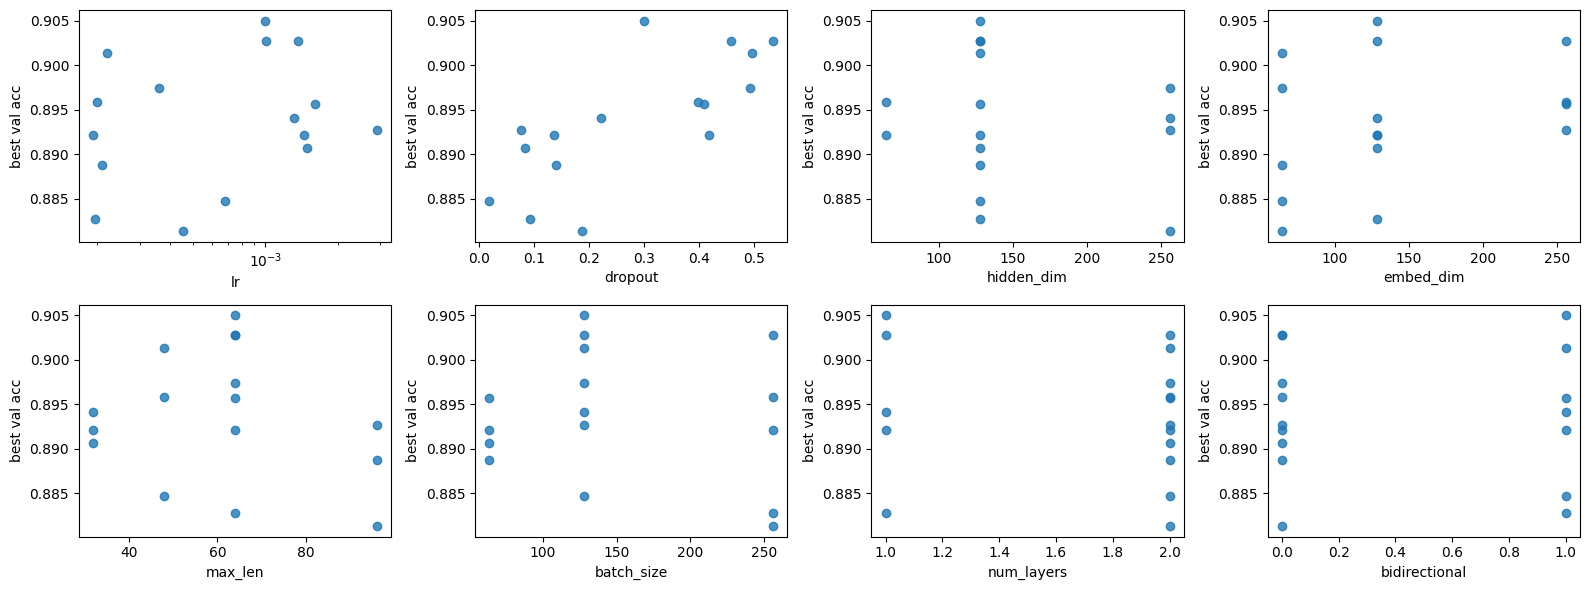


hidden_dim
              mean  count
hidden_dim               
64          0.8940      2
128         0.8947     10
256         0.8914      4

embed_dim
             mean  count
embed_dim               
64         0.8907      5
128        0.8942      7
256        0.8967      4

max_len
           mean  count
max_len               
32       0.8923      3
48       0.8940      3
64       0.8969      7
96       0.8876      3

batch_size
              mean  count
batch_size               
64          0.8918      4
128         0.8969      7
256         0.8910      5

num_layers
              mean  count
num_layers               
1           0.8953      5
2           0.8930     11

bidirectional
                 mean  count
bidirectional               
False          0.8938      9
True           0.8937      7


In [20]:
print("Baseline val acc:", round(float(df.loc[df.trial == 0, "best_val_acc"].iloc[0]), 4))
print("Best trial val acc:", round(float(df.best_val_acc.iloc[0]), 4))

params = ["lr", "dropout", "hidden_dim", "embed_dim", "max_len", "batch_size", "num_layers", "bidirectional"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, p in zip(axes.ravel(), params):
    ax.scatter(df[p].astype(float), df.best_val_acc, alpha=0.8)
    ax.set_xlabel(p)
    ax.set_ylabel("best val acc")
    if p == "lr":
        ax.set_xscale("log")
plt.tight_layout()
plt.show()

# Mean validation accuracy for each value of the discrete hyperparameters
for p in ["hidden_dim", "embed_dim", "max_len", "batch_size", "num_layers", "bidirectional"]:
    print(f"\n{p}")
    print(df.groupby(p).best_val_acc.agg(["mean", "count"]).round(4))

We see that 8 trials with dropout of 0.3 or higher average 89.0% validation accurancy, which weakest trials had dropout of 0.2 or lower. This suggest overfitting, likely from the 3.8M-parameter embedding table. So, we want to increase regularization, meaning higher dropout.

We retry the search with more narrow configurations.

I have also increased `TUNE_EPOCHS = 8`, where it used to be 4. And `N_TRIALS` of 15 to 30. 

In [36]:
def sample_config(rng):
    return dict(
        lr=float(10 ** rng.uniform(-3.7, -2.7)),   # 2e-4 .. 2e-3
        embed_dim=int(rng.choice([128, 256])),
        hidden_dim=int(rng.choice([128, 256])),
        num_layers=1,                               # fixed: no better, much slower
        bidirectional=True,                         # fixed: no measurable difference
        dropout=float(rng.uniform(0.3, 0.7)),       # focus here
        max_len=int(rng.choice([48, 64])),
        batch_size=128,                             # fixed
    )

search_rng = np.random.default_rng(SEED)
configs = [BASELINE] + [sample_config(search_rng) for _ in range(N_TRIALS)]
print(len(configs), "configs to try")

31 configs to try


In [37]:
results = []
for i, cfg in enumerate(configs):
    tag = "baseline" if i == 0 else f"trial {i:02d}"
    res = run_trial(cfg)
    results.append({"trial": i, **clean(cfg), **res})
    print(
        f"{tag:9s} val_acc {res['best_val_acc']:.4f} (epoch {res['best_epoch']}) | "
        f"lr {cfg['lr']:.1e} emb {cfg['embed_dim']} hid {cfg['hidden_dim']} L{cfg['num_layers']} "
        f"bi={cfg['bidirectional']} drop {cfg['dropout']:.2f} len {cfg['max_len']} bs {cfg['batch_size']} "
        f"| {res['seconds']}s"
    )

df = pd.DataFrame(results).sort_values("best_val_acc", ascending=False).reset_index(drop=True)
df.to_csv("tuning_results.csv", index=False)
df

baseline  val_acc 0.9050 (epoch 1) | lr 1.0e-03 emb 128 hid 128 L1 bi=True drop 0.30 len 64 bs 128 | 34.1s
trial 01  val_acc 0.9022 (epoch 1) | lr 1.2e-03 emb 256 hid 128 L1 bi=True drop 0.64 len 48 bs 128 | 35.5s
trial 02  val_acc 0.9045 (epoch 4) | lr 2.5e-04 emb 256 hid 256 L1 bi=True drop 0.60 len 64 bs 128 | 180.2s
trial 03  val_acc 0.9061 (epoch 1) | lr 1.2e-03 emb 256 hid 128 L1 bi=True drop 0.48 len 64 bs 128 | 44.4s
trial 04  val_acc 0.9071 (epoch 2) | lr 1.7e-03 emb 128 hid 256 L1 bi=True drop 0.63 len 64 bs 128 | 100.3s
trial 05  val_acc 0.9004 (epoch 3) | lr 5.5e-04 emb 128 hid 128 L1 bi=True drop 0.52 len 64 bs 128 | 57.5s
trial 06  val_acc 0.9028 (epoch 1) | lr 1.3e-03 emb 128 hid 128 L1 bi=True drop 0.60 len 64 bs 128 | 35.6s
trial 07  val_acc 0.9029 (epoch 5) | lr 4.5e-04 emb 128 hid 256 L1 bi=True drop 0.66 len 64 bs 128 | 169.0s
trial 08  val_acc 0.8969 (epoch 2) | lr 3.1e-04 emb 256 hid 128 L1 bi=True drop 0.32 len 48 bs 128 | 46.3s
trial 09  val_acc 0.9015 (epoch 3)

,trial,lr,embed_dim,hidden_dim,num_layers,bidirectional,dropout,max_len,batch_size,best_val_acc,best_epoch,epochs_run,val_loss_at_best,train_acc_at_best,seconds,params
0,4,0.001686,128,256,1,True,0.629105,64,128,0.907083,2,4,0.286133,0.929133,100.3,4630532
1,3,0.001219,256,128,1,True,0.480154,64,128,0.906083,1,3,0.292833,0.823000,44.4,8075268
2,13,0.001001,128,128,1,True,0.632904,48,128,0.905250,2,4,0.289350,0.923500,35.2,4104196
3,0,0.001000,128,128,1,True,0.300000,64,128,0.905000,1,3,0.294637,0.806533,34.1,4104196
4,2,0.000248,256,256,1,True,0.604456,64,128,0.904500,4,6,0.295197,0.939933,180.2,8732676
5,14,0.000487,256,256,1,True,0.572998,48,128,0.904083,2,4,0.292822,0.916667,91.5,8732676
6,16,0.000922,256,128,1,True,0.612292,64,128,0.903583,3,5,0.312736,0.953667,76.7,8075268
7,12,0.000933,128,256,1,True,0.633071,48,128,0.903500,3,5,0.291255,0.943733,91.8,4630532
8,29,0.000262,128,256,1,True,0.663432,48,128,0.903417,7,8,0.311122,0.953167,145.0,4630532
9,18,0.000930,128,256,1,True,0.526094,48,128,0.903083,2,4,0.286076,0.924033,82.6,4630532


Analyze this round of searching.

Baseline val acc: 0.905
Best trial val acc: 0.9071


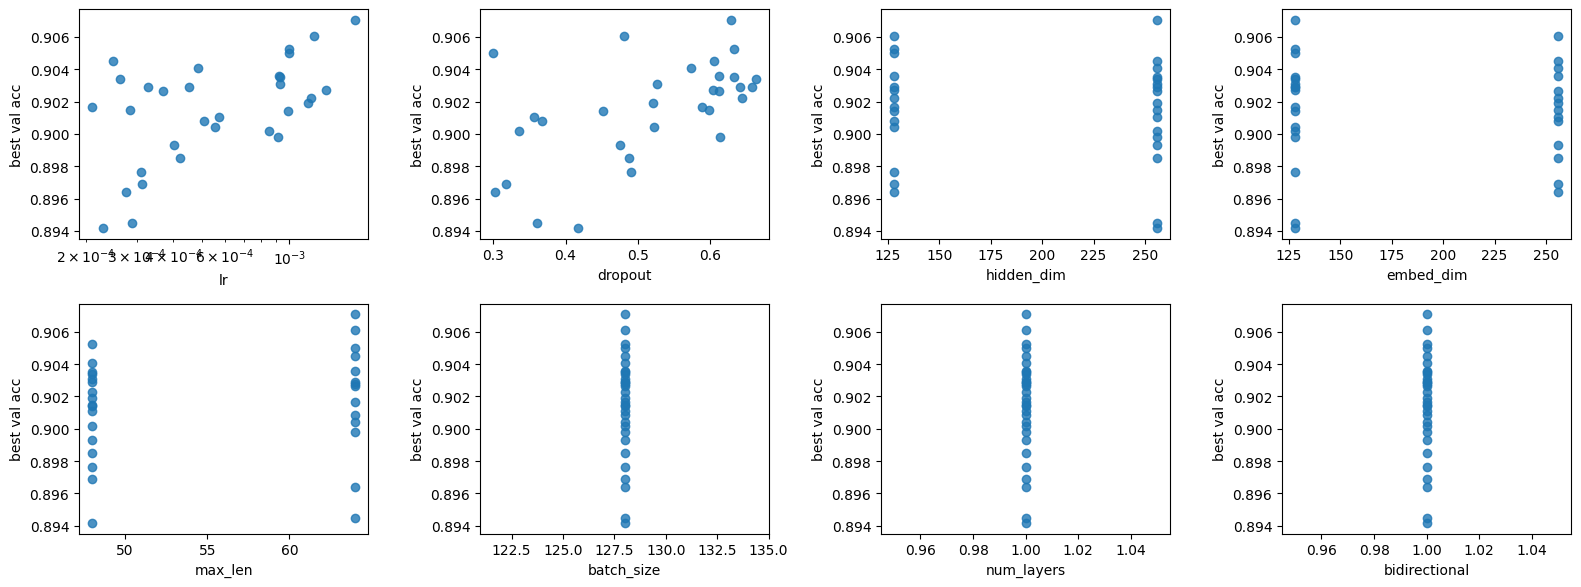


hidden_dim
              mean  count
hidden_dim               
128         0.9017     14
256         0.9013     17

embed_dim
             mean  count
embed_dim               
128        0.9015     17
256        0.9014     14

max_len
          mean  count
max_len              
48       0.901     17
64       0.902     14

batch_size
              mean  count
batch_size               
128         0.9015     31

num_layers
              mean  count
num_layers               
1           0.9015     31

bidirectional
                 mean  count
bidirectional               
True           0.9015     31


In [38]:
print("Baseline val acc:", round(float(df.loc[df.trial == 0, "best_val_acc"].iloc[0]), 4))
print("Best trial val acc:", round(float(df.best_val_acc.iloc[0]), 4))

params = ["lr", "dropout", "hidden_dim", "embed_dim", "max_len", "batch_size", "num_layers", "bidirectional"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, p in zip(axes.ravel(), params):
    ax.scatter(df[p].astype(float), df.best_val_acc, alpha=0.8)
    ax.set_xlabel(p)
    ax.set_ylabel("best val acc")
    if p == "lr":
        ax.set_xscale("log")
plt.tight_layout()
plt.show()

# Mean validation accuracy for each value of the discrete hyperparameters
for p in ["hidden_dim", "embed_dim", "max_len", "batch_size", "num_layers", "bidirectional"]:
    print(f"\n{p}")
    print(df.groupby(p).best_val_acc.agg(["mean", "count"]).round(4))

### Confirm the top configs across seeds

A random search winner is partly luck (random initialization and data order). Re-running the top configs
with other seeds gives a more honest ranking. Same budget settings as the search.

In [39]:
top_cfgs = df.head(TOP_K)[CFG_KEYS].to_dict("records")

confirm_rows = []
for j, cfg in enumerate(top_cfgs):
    accs = [run_trial(cfg, seed=s)["best_val_acc"] for s in CONFIRM_SEEDS]
    first = float(df.iloc[j].best_val_acc)  # the original search result for this config
    all_accs = [first] + accs
    confirm_rows.append({
        **clean(cfg),
        "search_val_acc": round(first, 4),
        "mean_val_acc": round(float(np.mean(all_accs)), 4),
        "std": round(float(np.std(all_accs)), 4),
    })
    print(f"config {j + 1}: runs {np.round(all_accs, 4)} -> mean {np.mean(all_accs):.4f}")

confirm_df = pd.DataFrame(confirm_rows).sort_values("mean_val_acc", ascending=False).reset_index(drop=True)
confirm_df

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/layers/layer.py:1101: UserWarning: Layer 'bidirectional' (of type Bidirectional) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/layers/layer.py:1101: UserWarning: Layer 'forward_lstm' (of type LSTM) was passed an input with a mask attached to it. However, this layer does not support masking and will

config 1: runs [0.9071 0.9055 0.9043] -> mean 0.9056
config 2: runs [0.9061 0.9046 0.9079] -> mean 0.9062
config 3: runs [0.9053 0.9005 0.9048] -> mean 0.9035


,lr,embed_dim,hidden_dim,num_layers,bidirectional,dropout,max_len,batch_size,search_val_acc,mean_val_acc,std
0,0.001219,256,128,1,True,0.480154,64,128,0.9061,0.9062,0.0014
1,0.001686,128,256,1,True,0.629105,64,128,0.9071,0.9056,0.0011
2,0.001001,128,128,1,True,0.632904,48,128,0.9053,0.9035,0.0021


In [40]:
best_cfg = clean(confirm_df.iloc[0][CFG_KEYS])
print("Selected configuration:")
for k, v in best_cfg.items():
    print(f"  {k}: {v}")

Selected configuration:
  lr: 0.0012191701060937745
  embed_dim: 256
  hidden_dim: 128
  num_layers: 1
  bidirectional: True
  dropout: 0.48015437515822684
  max_len: 64
  batch_size: 128


Skip the search, just run this to get the best configurations.

In [70]:
best_cfg = {
  "lr" : 0.0012191701060937745,
  "embed_dim" : 256,
  "hidden_dim" : 128,
  "num_layers" : 1,
  "bidirectional" : True,
  "dropout" : 0.48015437515822684,
  "max_len" : 64,
  "batch_size" : 128
}

# Final training on the full training set

Now the winner is trained on all of the training split. It runs for 20 epochs, where one epoch is 100 steps. This means we evaluate the validation accuracy at a resolution of 100 steps. `ModelCheckpoint` keeps
the best epoch's weights, and `load_weights` restores them before the single test evaluation.

In [71]:
def train_final(cfg, epochs=20, ckpt_path="best_tuned.weights.h5"):
    cfg = clean(cfg)
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    ml = cfg["max_len"]

    train_ds = make_ds(X_train[:, :ml], y_train, cfg["batch_size"], shuffle=True)
    val_ds = make_ds(X_val[:, :ml], y_val, cfg["batch_size"])

    model = make_model(cfg)
    history = model.fit(
        train_ds, validation_data=val_ds, steps_per_epoch= 300, epochs=epochs,
        callbacks=[keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor="val_accuracy", mode="max",
            save_best_only=True, save_weights_only=True)],
    )
    model.load_weights(ckpt_path)  # restore the best epoch
    return model, history


final_model, final_history = train_final(best_cfg)
final_model.summary()
best_epoch = int(np.argmax(final_history.history["val_accuracy"])) + 1
print(f"\nBest validation accuracy: {max(final_history.history['val_accuracy']):.4f} (epoch {best_epoch})")

Epoch 1/20


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/layers/layer.py:1101: UserWarning: Layer 'bidirectional' (of type Bidirectional) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/layers/layer.py:1101: UserWarning: Layer 'forward_lstm' (of type LSTM) was passed an input with a mask attached to it. However, this layer does not support masking and will

300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 59ms/step - accuracy: 0.8372 - loss: 0.4512 - val_accuracy: 0.9084 - val_loss: 0.2826
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.9096 - loss: 0.2785 - val_accuracy: 0.9141 - val_loss: 0.2651
Epoch 3/20
244/300 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.9137 - loss: 0.2611

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


300/300 ━━━━━━━━━━━━━━━━━━━━ 15s 51ms/step - accuracy: 0.9137 - loss: 0.2611 - val_accuracy: 0.9178 - val_loss: 0.2538
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 62ms/step - accuracy: 0.9413 - loss: 0.1792 - val_accuracy: 0.9135 - val_loss: 0.2661
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 62ms/step - accuracy: 0.9366 - loss: 0.1927 - val_accuracy: 0.9157 - val_loss: 0.2571
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 15s 52ms/step - accuracy: 0.9365 - loss: 0.1906 - val_accuracy: 0.9154 - val_loss: 0.2514
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - accuracy: 0.9589 - loss: 0.1231 - val_accuracy: 0.9179 - val_loss: 0.2643
Epoch 8/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - accuracy: 0.9519 - loss: 0.1405 - val_accuracy: 0.9160 - val_loss: 0.2687
Epoch 9/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 15s 51ms/step - accuracy: 0.9474 - loss: 0.1517 - val_accuracy: 0.9118 - val_loss: 0.2743
Epoch 10/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.9693 - loss: 0.0895 - val_accura

Model: "functional"

... (2 outputs left out)

 Trainable params: 8,075,268 (30.80 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 16,150,538 (61.61 MB)


Best validation accuracy: 0.9179 (epoch 7)


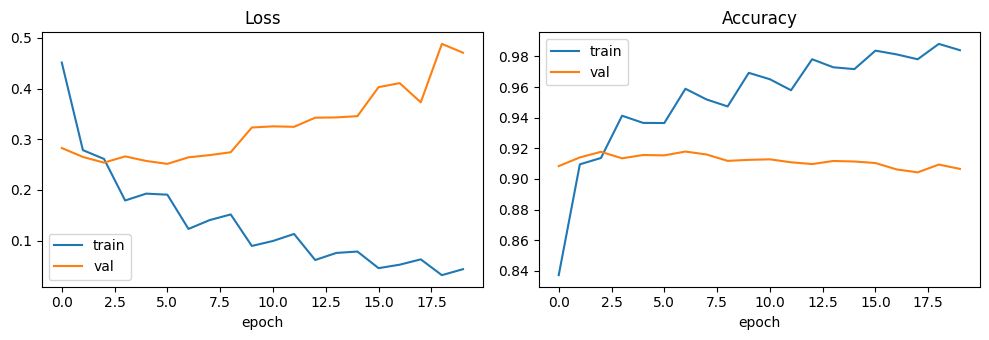

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, key, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(final_history.history[key], label="train")
    ax.plot(final_history.history["val_" + key], label="val")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.show()

Training loss continues to decrease and training accuracy continues to increase. Validation loss decreases, then starts to increase with more training. This indicates that the model has learned the data after around 5 epochs (5 * 300 examples) and has started to overfit.

## Test Set Evaluation

In [73]:
ml = best_cfg["max_len"]
test_ds = make_ds(X_test[:, :ml], y_test, best_cfg["batch_size"])
te_loss, te_acc = final_model.evaluate(test_ds, verbose=0)
print(f"Test loss {te_loss:.4f} | test accuracy {te_acc:.4f}")

baseline_val = float(df.loc[df.trial == 0, "best_val_acc"].iloc[0])
print(f"(Baseline val acc during search was {baseline_val:.4f}, on a {TUNE_TRAIN_SIZE or 'full'}-example training set)")

Test loss 0.2739 | test accuracy 0.9124
(Baseline val acc during search was 0.9050, on a 30000-example training set)


In [74]:
# Per-class accuracy (test_ds is not shuffled, so order matches test_labels)
logits = final_model.predict(test_ds, verbose=0)
preds = logits.argmax(axis=1)

for i, name in enumerate(CLASSES):
    mask = y_test == i
    print(f"{name:9s} {(preds[mask] == i).mean():.4f}")

World     0.9016
Sports    0.9784
Business  0.8532
Sci/Tech  0.9163


# Try your own headlines

In [76]:
ML = best_cfg["max_len"]  # the winning config's sequence length


def predict(text):
    # The vectorizer outputs CAP_LEN (128) ids, but the final model expects exactly ML,
    # so slice to the first ML columns (same as truncating at ML).
    ids = vectorizer(tf.constant([text])).numpy()[:, :ML].astype("int32")
    probs = tf.nn.softmax(final_model(ids, training=False), axis=-1).numpy()[0]
    top = int(probs.argmax())
    return CLASSES[top], float(probs[top]), probs

# took some headlines from the news
samples = [
    "Former MP Navdeep Bains eked out a narrow victory Saturday to become the next Ontario Liberal leader, pledging to focus now on getting the party in fighting shape for the next election.",
    "A senior adviser to U.S. President Donald Trump is once again hurling insults and threats at the federal government as trade negotiations between Canada and the U.S. continue.",
    "A new study finds that Ottawa's hospitals had some of the longest emergency room stay times in Ontario.",
    "McIlroy, fresh off capturing his eighth Race to Dubai title on the DP World Tour, tying the all-time record, attended the Toronto Maple Leafs game versus the Los Angeles Kings Thursday night.",
    "Some Etsy sellers across Canada are removing products from the platform amid criticism for introducing artificial intelligence model training as part of a policy change." # should be business
    ]

for s in samples:
    label, conf, probs = predict(s)
    print(f"[{label:8s} {conf:.2f}] {s}")
    print("   " + " | ".join(f"{c} {p:.2f}" for c, p in zip(CLASSES, probs)))

[World    0.99] Former MP Navdeep Bains eked out a narrow victory Saturday to become the next Ontario Liberal leader, pledging to focus now on getting the party in fighting shape for the next election.
   World 0.99 | Sports 0.00 | Business 0.00 | Sci/Tech 0.01
[Business 0.95] A senior adviser to U.S. President Donald Trump is once again hurling insults and threats at the federal government as trade negotiations between Canada and the U.S. continue.
   World 0.03 | Sports 0.01 | Business 0.95 | Sci/Tech 0.01
[Sci/Tech 0.92] A new study finds that Ottawa's hospitals had some of the longest emergency room stay times in Ontario.
   World 0.02 | Sports 0.00 | Business 0.06 | Sci/Tech 0.92
[Sports   0.99] McIlroy, fresh off capturing his eighth Race to Dubai title on the DP World Tour, tying the all-time record, attended the Toronto Maple Leafs game versus the Los Angeles Kings Thursday night.
   World 0.01 | Sports 0.99 | Business 0.00 | Sci/Tech 0.00
[World    0.64] Some Etsy sellers acro